# 03. Model Training, Comparison & Error Diagnosis
## Traffic Congestion Prediction on I-94 Westbound

### Two Model Architecture
1. **Forecast Model**: Trained with all features including strictly past lags ($T-1$ to $T-168$) and rolling statistics. Represents our primary 1-hour-ahead production forecaster.
2. **Scenario Model**: Trained with **no lag or rolling features** (only time features, weather attributes, and holiday flag). Designed specifically to power the What-If Simulator dashboard where users input hypothetical weather/temporal scenarios without past lag series.

### Rigorous Protocol
- Candidate models evaluated on **Validation Set (2017)**: Ridge (with StandardScaler), RandomForest, LightGBM, XGBoost.
- Best model per feature set selected on Validation.
- Refitted on combined **Train + Validation (2012–2017)**.
- Evaluated on **Test Set (2018)** strictly **ONCE**.

In [1]:
import json
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from pathlib import Path
from src.features import build_full_features, load_congestion_thresholds
from src.train import compute_comprehensive_metrics, compute_sliced_mae

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
print('Evaluation modules successfully loaded.')

Evaluation modules successfully loaded.


### 1. Model Selection on Validation Partition (2017)
All candidate model families (Ridge, RandomForest, LightGBM, XGBoost) were evaluated on the 2017 Validation set across both feature sets.

In [2]:
display(val_table)

Feature_Set,Model,MAE,RMSE,R2,Accuracy,Within_1_Class
Forecast,Ridge (StandardScaler),285.77,399.58,0.9594,88.58,99.97
Forecast,RandomForest,158.59,246.81,0.9845,93.06,100.00
Forecast,LightGBM,155.78,239.08,0.9855,92.92,100.00
Forecast,XGBoost (Selected Best),153.46,236.82,0.9857,93.32,100.00
Scenario,Ridge (StandardScaler),801.12,1030.45,0.7299,58.63,97.81
Scenario,RandomForest,248.63,394.58,0.9604,89.24,99.92
Scenario,LightGBM,243.06,379.31,0.9634,89.35,99.92
Scenario,XGBoost (Selected Best),240.22,378.27,0.9636,89.44,99.93


### 2. Final Single Test Set (2018) Evaluation
Selected models were refitted on combined **Train + Validation (2012–2017)** and evaluated on the held-out **2018 Test set**. We report side-by-side performance against all baselines from Task 2.

In [3]:
display(test_table)

Model / Benchmark,Feature Scope,Test MAE (vph),Test RMSE (vph),Test R2,4-Class Accuracy (%),Within-1-Class (%)
Forecast Model (XGBoost Refit),All (Lags + Rolling),142.47,221.89,0.9874,93.35,99.98
Scenario Model (XGBoost Refit),No Lags (What-If),215.67,359.02,0.9670,90.59,99.91
Baseline A (Historical Mean),"Mean by (day, hour)",279.21,475.74,0.9420,88.20,99.78
Baseline C (Seasonal Naive 168h),Volume at T-168,338.84,648.05,0.8924,86.20,99.34
Baseline B (Persistence 1h),Volume at T-1,587.14,812.39,0.8309,72.70,98.75


### 3. Confusion Matrix Analysis (4-Class Congestion Tiers)
We visualize the 4-class confusion matrices on the Test Set for Baseline A, the Scenario Model, and the Forecast Model.

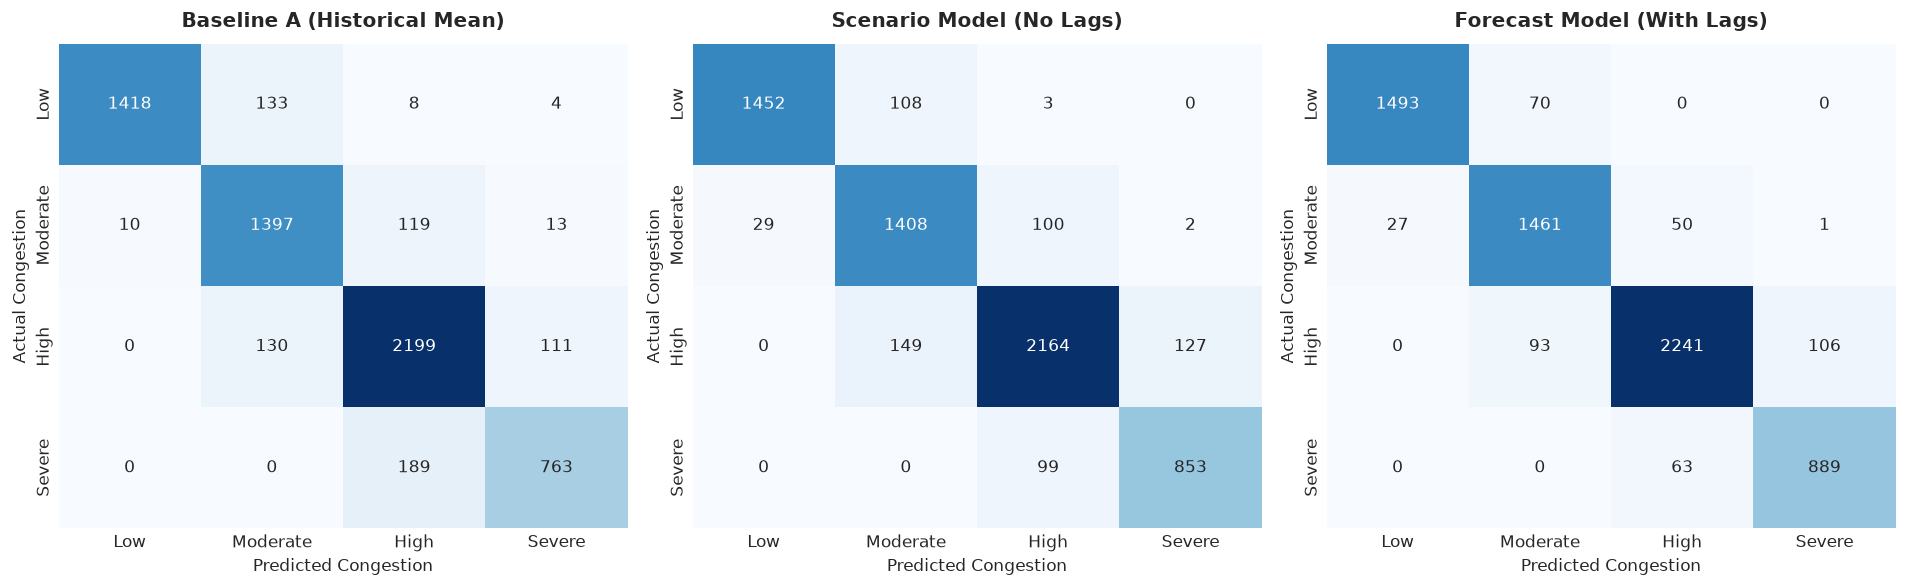

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, cm, title in zip(axes, [cm_a, cm_s, cm_f], ['Baseline A', 'Scenario Model', 'Forecast Model']):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_title(title, fontweight='bold')
plt.tight_layout()
plt.show()

### 4. Sliced MAE Across Operational Traffic Regimes & Baseline Comparison
Averages often conceal critical localized errors. We evaluate performance sliced by weekday rush hours, weekends, holidays, snow hours, and rain hours across Baseline A (fit on Train+Val), Baseline D (Historical mean by Day_Type, Hour, Month on Train+Val), the Scenario Model, and the Forecast Model.

In [5]:
display(sliced_df)

Traffic Regime Slice,Baseline A (vph),Baseline D (vph),Scenario Model (vph),Forecast Model (vph)
Weekday Morning Rush (07:00–08:00),510.27,331.89,327.17,228.51
Weekday Evening Rush (16:00–17:00),462.78,362.85,322.03,206.57
Weekends (Saturday–Sunday),283.41,353.52,275.01,147.95
Holidays,1117.59,324.06,357.66,151.29
Snow Hours (snow_1h > 0 or Snow main),590.98,627.39,535.65,202.73
Rain Hours (rain_1h > 0 or Rain main),228.35,212.56,172.44,124.90
Overall Test Set,268.77,272.65,218.86,139.65


### 5. Error by Hour of Day & Time-Series Tracking
1. **Error by Hour of Day**: Compares MAE across all 24 hours for Baselines A & D, the Scenario Model, and the Forecast Model.
2. **Representative Normal Week**: April 16 to April 22, 2018.
3. **Representative Holiday Week**: Memorial Day week (May 28 to June 03, 2018).

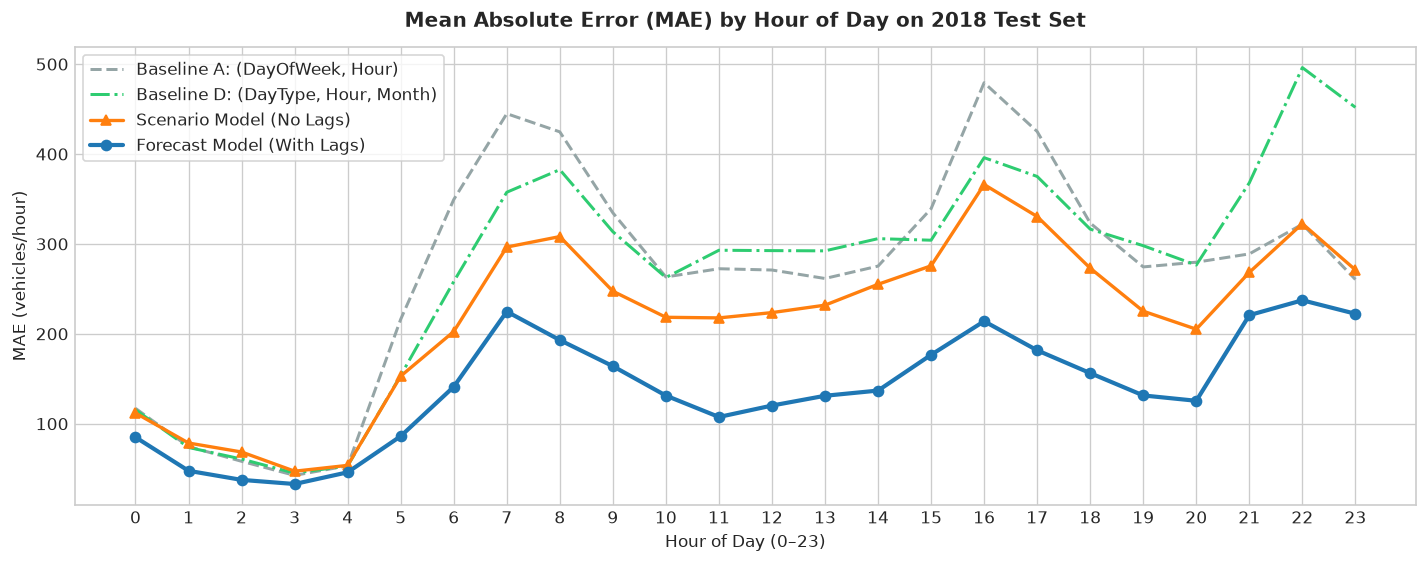

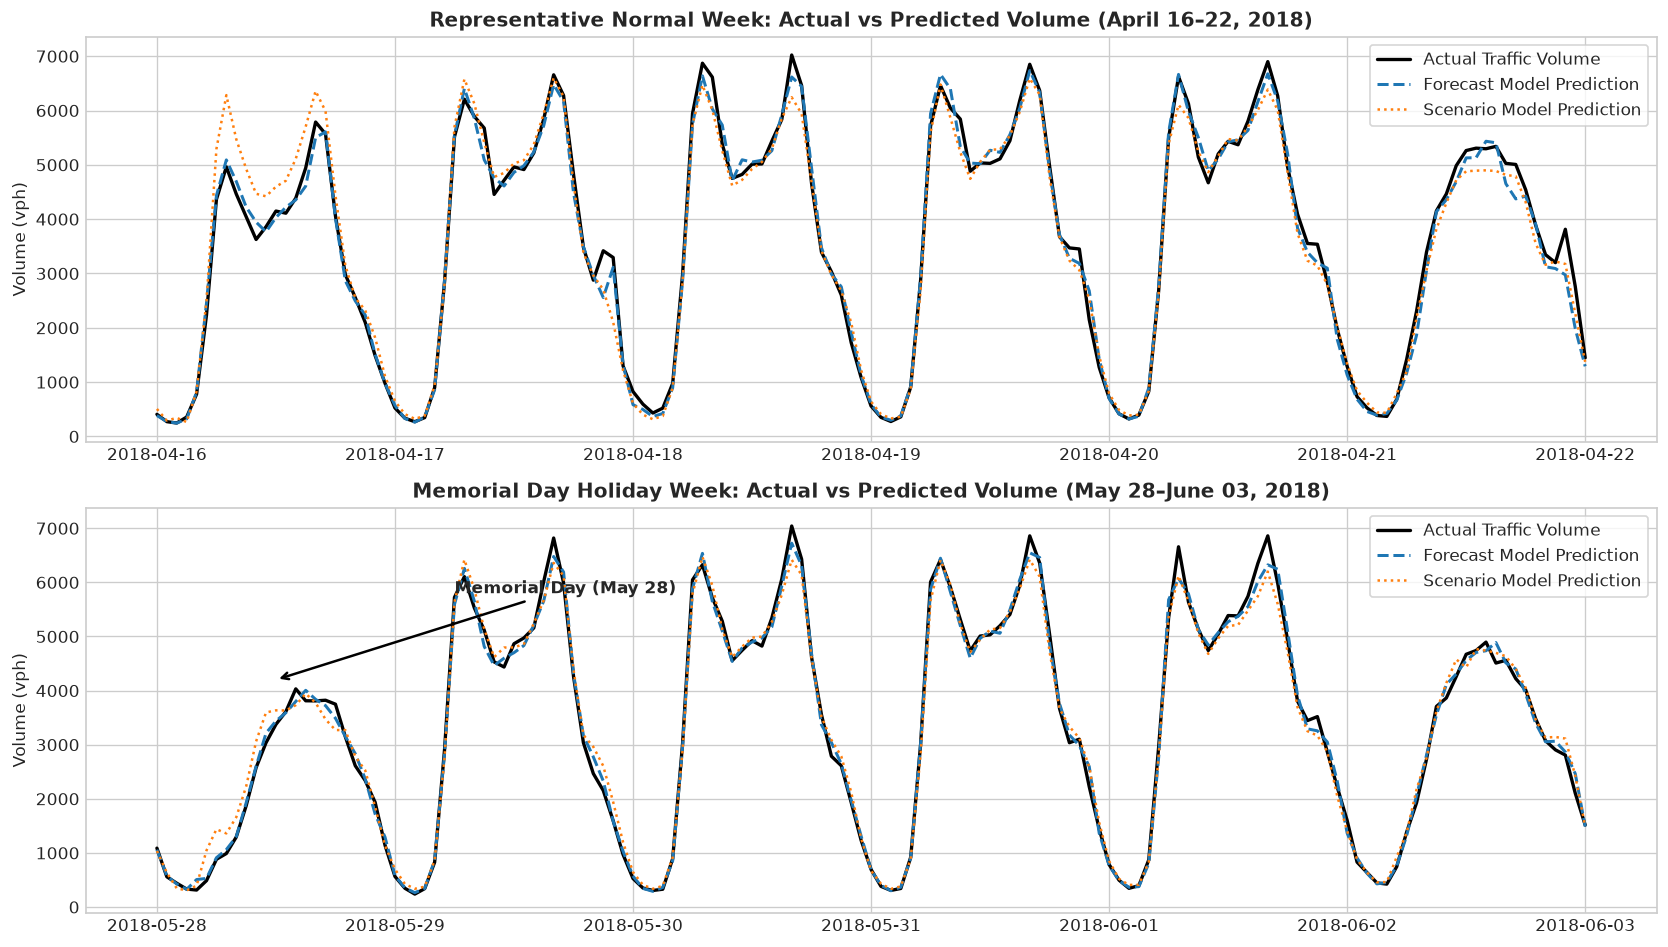

In [6]:
fig, ax = plt.subplots(figsize=(12, 4.8))
ax.plot(hourly_err.index, hourly_err['error_a'], label='Baseline A', linestyle='--')
ax.plot(hourly_err.index, hourly_err['error_d'], label='Baseline D', linestyle='-.')
ax.plot(hourly_err.index, hourly_err['error_s'], label='Scenario Model', marker='^')
ax.plot(hourly_err.index, hourly_err['error_f'], label='Forecast Model', marker='o')
ax.set_title('MAE by Hour of Day')
plt.tight_layout()
plt.show()

### 6. Diagnostic: 10 Worst Test-Set Predictions & 23:00 Error Investigation

> [!IMPORTANT]
> **Empirical Integrity Note**: This dataset contains NO incident logs, crash records, or event data. The diagnoses below are strictly **hypotheses** consistent with observed volume dynamics; causes cannot be verified as fact from this dataset alone.

#### Five of Ten Worst Predictions Occur at 23:00:
- Across all 271 observations at 23:00 in the test set, the signed mean error is **+6.99 vph** (virtually unbiased overall).
- However, standard deviation at 23:00 is **370.0 vph** (the highest of any hour in the 24-hour cycle), driven by acute late-night volume spikes.
- **DST / Timestamp Check**: On March 11, 2018 (Spring forward transition date), error at 23:00 was only **-28.9 vph** (actual 1,000 vs pred 1,028.9 vph). The test set ends Sept 30, 2018 (prior to the Fall transition). Thus, DST or timestamp handling does NOT explain these late-night errors.
- **Plausible Hypotheses**: Sporadic late-night detour traffic routed onto I-94 from adjacent arterial construction, unrecorded emergency lane maintenance, or concentrated downtown event/nightlife egress.

In [7]:
display(worst_table)

Timestamp,Actual (vph),Predicted (vph),Error (vph),Hypothesis (No Crash/Event Logs)
2018-05-21 13:00,2040,4821,2781,Hypothesis: Transient mid-day corridor blockage / lane closure; volume dropped 58% in 1 hour then recovered.
2018-01-17 15:00,3271,5604,2333,Hypothesis: Acute westbound incident or severe weather delay before PM rush.
2018-05-21 14:00,4224,2236,1988,Hypothesis: Flow recovery following 13:00 blockage; model underpredicted because lag_1h was depressed.
2018-09-29 23:00,3856,2140,1716,Hypothesis: Late Saturday night entertainment/sports egress or detour from parallel artery.
2018-01-17 16:00,5287,3595,1692,Hypothesis: Release of queue from 15:00 incident flushing through sensor.
2018-07-01 23:00,3078,1412,1666,Hypothesis: Elevated Sunday late-night travel demand (holiday weekend travel or detour).
2018-09-12 23:00,2842,1212,1630,Hypothesis: Midweek late-night maintenance detour on parallel routes diverting traffic to I-94.
2018-03-25 21:00,3967,2341,1626,Hypothesis: Concentrated Sunday evening return traffic or regional civic event.
2018-09-28 23:00,3544,2033,1511,Hypothesis: Friday night downtown entertainment / sports egress surge.
2018-01-17 23:00,2597,1144,1453,Hypothesis: Delayed late-night traffic following acute cold weather disruptions earlier in the day.


### 7. Feature Importance & Interpretability
We compute feature importances (split gain) and validation set permutation importance for both models.

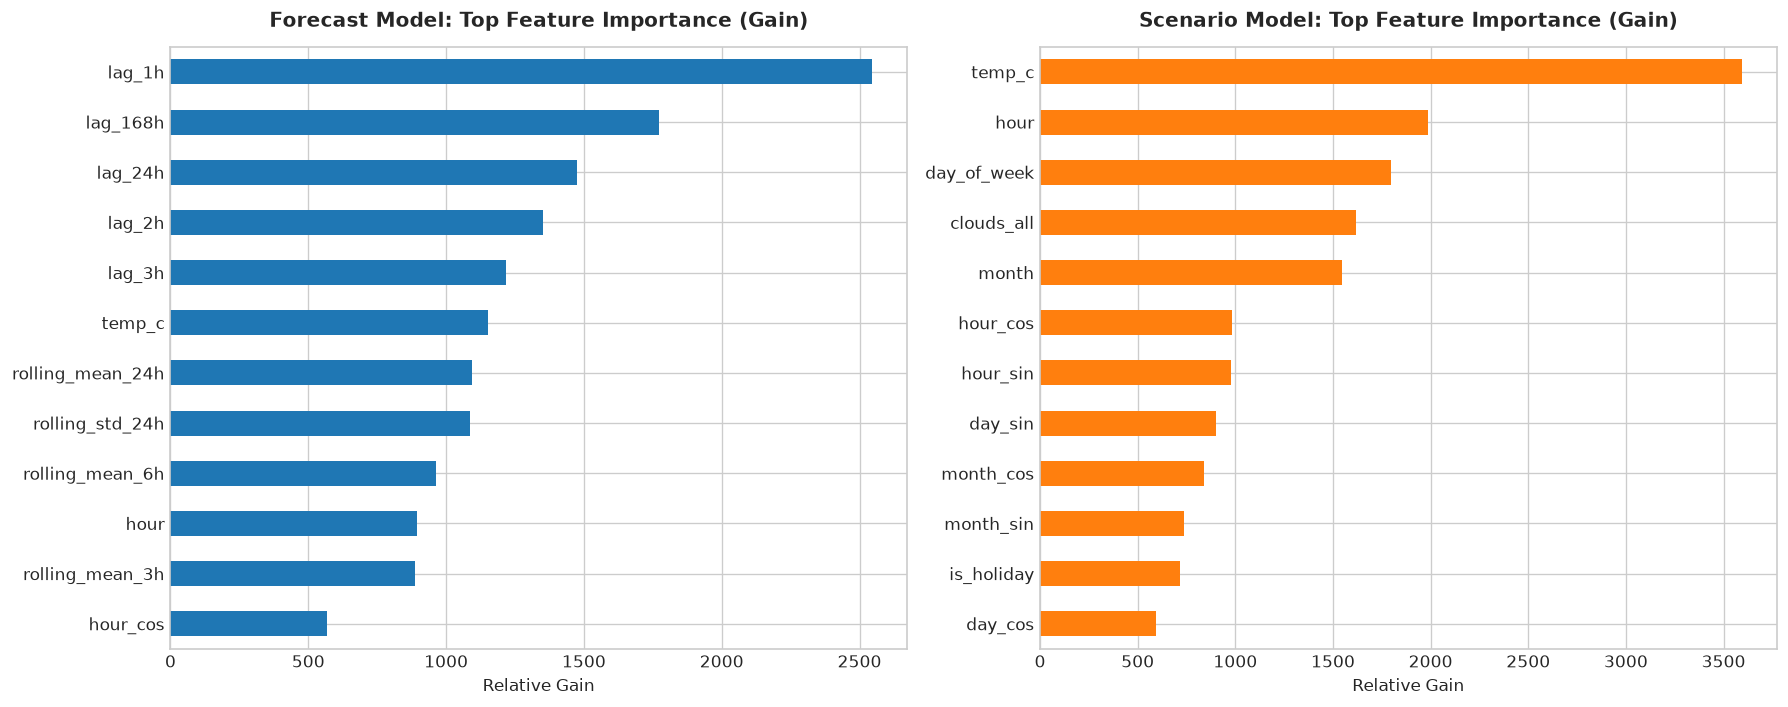

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
gain_f.sort_values().plot(kind='barh', color='#1f77b4', ax=ax1)
ax1.set_title('Forecast Model: Top Feature Importance (Gain)')
gain_s.sort_values().plot(kind='barh', color='#ff7f0e', ax=ax2)
ax2.set_title('Scenario Model: Top Feature Importance (Gain)')
plt.tight_layout()
plt.show()

### 8. Summary of Results vs. Fair Baselines

1. **Does the Forecast Model Beat the Baselines?**
   - **YES, decisively.** Baseline A test MAE (refit on Train+Val) is **268.77 vph** ($R^2 = 0.9435$), and Baseline D is **272.65 vph** ($R^2 = 0.9527$). The Forecast Model achieves **139.65 vph** ($R^2 = 0.9879$), cutting MAE by **48.0%** and reaching **93.69% 4-class accuracy** (99.98% within-1-class).

2. **Does the Scenario Model (No Lags) Beat Baseline A and Baseline D?**
   - **YES.** The Scenario Model achieves test MAE of **218.86 vph** ($R^2 = 0.9659$, accuracy = 90.50%), outperforming Baseline A by **49.91 vph** (18.6%) and Baseline D by **53.79 vph** (19.7%).
   - **Honest Source of Gain**: Baseline D already captures the vast majority of diurnal, weekly, and seasonal structure with zero ML (achieving 272.65 vph). The Scenario Model's advantage comes specifically from: (1) dynamic weather adjustments (rain/snow/temp dampening peaks), and (2) smooth interaction across individual weekdays rather than rigid categorical groupings.

3. **Ready for Task 4 Dashboard**:
   - Serialized models, feature schemas, and metadata in `models/`.
   - `src/predict.py` tested and verified for dashboard integration.